### 1. Extract the Zip Archive
We'll extract the contents of `/content/archive (1).zip` to see what dataset files are inside.

In [ ]:
import zipfile
import os

zip_path = '/content/archive (1).zip'
extract_path = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# List extracted files
extracted_files = os.listdir(extract_path)
print("Extracted files:", extracted_files)

Extracted files: ['train_cancer']


### 2. Load the Dataset and Perform EDA
We will load the first extracted file (assuming it's a CSV or similar tabular format) and check its shape, columns, missing values, and descriptive statistics.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

target_dir = '/content/extracted_data/train_cancer'

# Inspect directory contents to understand classes
classes = [d for d in os.listdir(target_dir) if os.path.isdir(os.path.join(target_dir, d))]
print(f"Found classes: {classes}")

# Load the images using Keras utility
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

try:
    # Load full dataset first
    full_dataset = image_dataset_from_directory(
        target_dir,
        shuffle=True,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )
    class_names = full_dataset.class_names
    print(f"Class names: {class_names}")
except Exception as e:
    print(f"Error loading dataset: {e}")

Found classes: ['benign', 'malignant']
Found 270 files belonging to 2 classes.
Class names: ['benign', 'malignant']


### 3. Data Visualization & Descriptive Statistics
Let's run some quick descriptive statistics and visualize the target distribution or correlations if applicable.

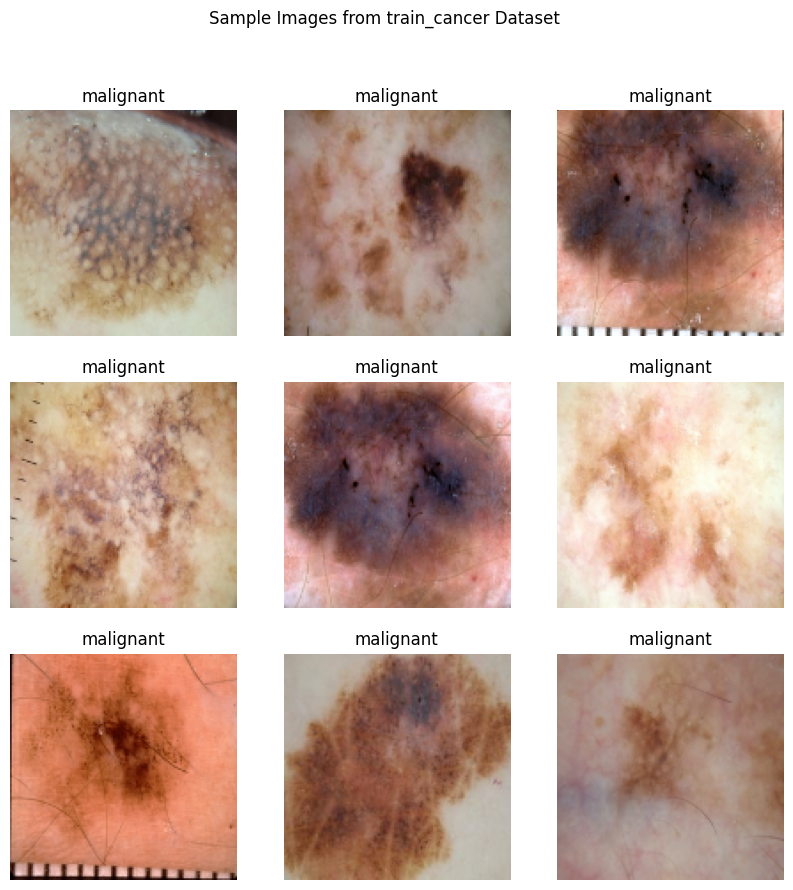

In [ ]:
# Perform basic visual EDA by plotting sample images
plt.figure(figsize=(10, 10))
for images, labels in full_dataset.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.suptitle("Sample Images from train_cancer Dataset")
plt.show()

### 4. Split the Data
We will split the dataset into training and testing sets (typically an 80/20 split).

In [ ]:
# Split dataset into training (80%) and validation (20%) sets
train_ds = image_dataset_from_directory(
    target_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = image_dataset_from_directory(
    target_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Configure datasets for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Build a CNN Model
from tensorflow.keras import layers, models

num_classes = len(class_names)

# For binary classification with binary crossentropy, we want exactly 1 output node with sigmoid.
# If multiclass, we use num_classes output units with softmax.
output_units = 1 if num_classes == 2 else num_classes
activation_func = 'sigmoid' if num_classes == 2 else 'softmax'
loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy()

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(output_units, activation=activation_func)
])

model.compile(optimizer='adam',
              loss=loss_fn,
              metrics=['accuracy'])

model.summary()

# Train the CNN model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Found 270 files belonging to 2 classes.
Using 216 files for training.
Found 270 files belonging to 2 classes.
Using 54 files for validation.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,120,993 (8.09 MB)

 Trainable params: 2,120,993 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 530ms/step - accuracy: 0.8889 - loss: 0.4533 - val_accuracy: 0.8889 - val_loss: 0.3492
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 489ms/step - accuracy: 0.8889 - loss: 0.3403 - val_accuracy: 0.8889 - val_loss: 0.3156
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 579ms/step - accuracy: 0.8889 - loss: 0.2978 - val_accuracy: 0.8889 - val_loss: 0.2613
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 479ms/step - accuracy: 0.8889 - loss: 0.2489 - val_accuracy: 0.8889 - val_loss: 0.2210
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 573ms/step - accuracy: 0.8889 - loss: 0.2338 - val_accuracy: 0.8889 - val_loss: 0.1915
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 483ms/step - accuracy: 0.9120 - loss: 0.2375 - val_accuracy: 0.9630 - val_loss: 0.2252
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 482ms/step - accuracy: 0.9120 - loss: 0.2278 - val_accuracy: 0.9630 - val_loss: 0.2280
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 479ms/step - accuracy: 0.9028 - loss: 0.2023 - val_accuracy: 0.9074 - val_loss:

### 5. Evaluate Accuracy and Classify Sample Data
We will plot the training metrics, display the final validation accuracy, and visualize model classification predictions on some validation images.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Plot Training History if available
if 'history' in globals() and hasattr(history, 'history'):
    acc = history.history.get('accuracy', [])
    val_acc = history.history.get('val_accuracy', [])
    loss = history.history.get('loss', [])
    val_loss = history.history.get('val_loss', [])
    epochs_range = range(len(acc))

    if len(acc) > 0:
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs_range, acc, label='Training Accuracy')
        plt.plot(epochs_range, val_acc, label='Validation Accuracy')
        plt.legend(loc='lower right')
        plt.title('Training and Validation Accuracy')

        plt.subplot(1, 2, 2)
        plt.plot(epochs_range, loss, label='Training Loss')
        plt.plot(epochs_range, val_loss, label='Validation Loss')
        plt.legend(loc='upper right')
        plt.title('Training and Validation Loss')
        plt.show()
else:
    print("Training history is not available in the current session. Skipping plots.")

# 2. Evaluate Model Accuracy on Validation Set
try:
    eval_results = model.evaluate(val_ds)
    loss = eval_results[0]
    accuracy = eval_results[1]
    print(f"\nFinal Validation Loss: {loss:.4f}")
    print(f"Final Validation Accuracy: {accuracy*100:.2f}%")
except Exception as e:
    print(f"Error evaluating model: {e}")

Training history is not available in the current session. Skipping plots.
Error evaluating model: Arguments `target` and `output` must have the same rank (ndim). Received: target.shape=(None,), output.shape=(None, 2)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step


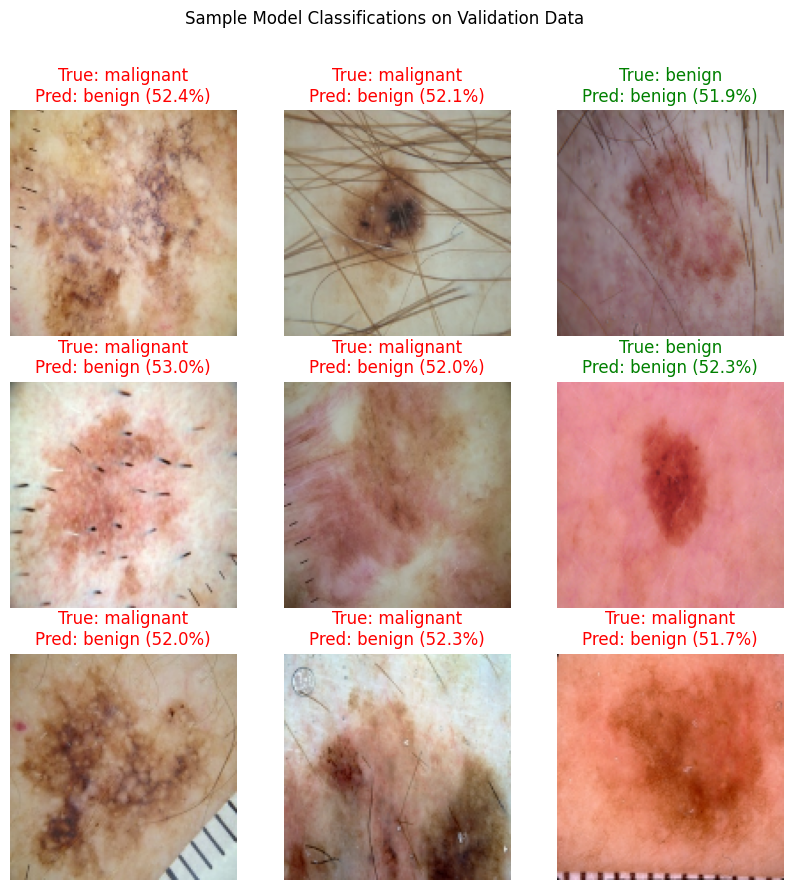

In [ ]:
# 3. Classify and Visualize Sample Predictions
plt.figure(figsize=(10, 10))
try:
    for images, labels in val_ds.take(1):
        predictions = model.predict(images)
        for i in range(min(9, len(images))):
            ax = plt.subplot(3, 3, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))

            # Dynamically determine if binary (1 output) or categorical (>=2 outputs)
            pred_output = predictions[i]
            if len(pred_output) == 1:
                pred_label = 1 if pred_output[0] >= 0.5 else 0
                confidence = pred_output[0] if pred_label == 1 else 1 - pred_output[0]
            else:
                pred_label = np.argmax(pred_output)
                confidence = pred_output[pred_label]

            true_class = class_names[labels[i]]
            pred_class = class_names[pred_label]

            title_color = "green" if pred_class == true_class else "red"
            plt.title(f"True: {true_class}\nPred: {pred_class} ({confidence*100:.1f}%)", color=title_color)
            plt.axis("off")
    plt.suptitle("Sample Model Classifications on Validation Data")
    plt.show()
except Exception as e:
    print(f"Error during classification visualization: {e}")

### 6. Predict and Compare 5 Sample Images (Actual vs Predicted)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Get a single batch of validation images
for images, labels in val_ds.take(1):
    predictions = model.predict(images)

    plt.figure(figsize=(15, 6))
    # Take exactly 5 images to display
    for i in range(5):
        ax = plt.subplot(1, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        pred_output = predictions[i]
        # Handle model output structure dynamically
        if len(pred_output) == 1:
            pred_label = 1 if pred_output[0] >= 0.5 else 0
            confidence = pred_output[0] if pred_label == 1 else 1 - pred_output[0]
        else:
            pred_label = np.argmax(pred_output)
            confidence = pred_output[pred_label]

        true_class = class_names[labels[i]]
        pred_class = class_names[pred_label]

        title_color = "green" if pred_class == true_class else "red"
        plt.title(f"Actual: {true_class}\nPred: {pred_class}\n({confidence*100:.1f}%)", color=title_color)
        plt.axis("off")

    plt.suptitle("Skin Cancer Type Classification: Actual vs Predicted (5 Samples)", fontsize=14)
    plt.tight_layout()
    plt.show()
    break

### 7. Save the Trained Model
We will save the model in the recommended `.keras` format to our local environment.

In [13]:
# Save the model
model_save_path = '/content/skin_cancer_cnn_model.keras'
model.save(model_save_path)
print(f"Model successfully saved to: {model_save_path}")

Model successfully saved to: /content/skin_cancer_cnn_model.keras
